In [1]:
import sys
sys.path.append("./../")
sys.path.append("./../../") 

import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors

from scripts.utils import load_array

from scripts.cshap.decomposition.DWT_decomposition import DWTDecomposition
from scripts.cshap.decomposition.EMD_decomposition import EMDDecomposition
from scripts.cshap.decomposition.custom_decomposition import CustomDecomposition

In [2]:
colors = ["#A338C4", '#248EF1', "#29BA10", '#F68D0E', '#F12476']

OPPORTUNITY

In [3]:
dataset = 'opportunity_uni'
decomposition_def = 'trend+bias+scale*(low_freq+var*high_freq)'
var_window_size = 27
noise_sigma = 1

In [4]:
if decomposition_def == 'EMD':
    decomposition = EMDDecomposition(max_imfs=4)
elif decomposition_def == 'DWT':
    decomposition = DWTDecomposition(level=3)
else:
    # var_window_size = int(var_window_fraq * X_train.shape[1])
    decomposition = CustomDecomposition(decomposition_def, noise_sigma=noise_sigma, var_window_size=var_window_size)

In [5]:
result_path = '/home/annemarie/2024-CSHAP-PhDAnnemarie/data/results/' + dataset + '/'

In [6]:
performance = 75.78

In [7]:
single_insertion_path = result_path + 'single_insertion.pkl'
single_deletion_path = result_path + 'single_deletion.pkl'

In [8]:
insert_res_dict = load_array(single_insertion_path)
delete_res_dict = load_array(single_deletion_path)

In [9]:
mean_res_insert_opp = [np.mean(np.array(v) - performance) for v in insert_res_dict.values()]
std_res_insert_opp = [np.std(np.array(v) - performance) for v in insert_res_dict.values()]

mean_res_delete_opp = [np.mean(np.array(v) - performance) for v in list(delete_res_dict.values())[:-1]]
std_res_delete_opp = [np.std(np.array(v) - performance) for v in list(delete_res_dict.values())[:-1]]

Text(0.5, 1.0, 'Feasibility analysis')

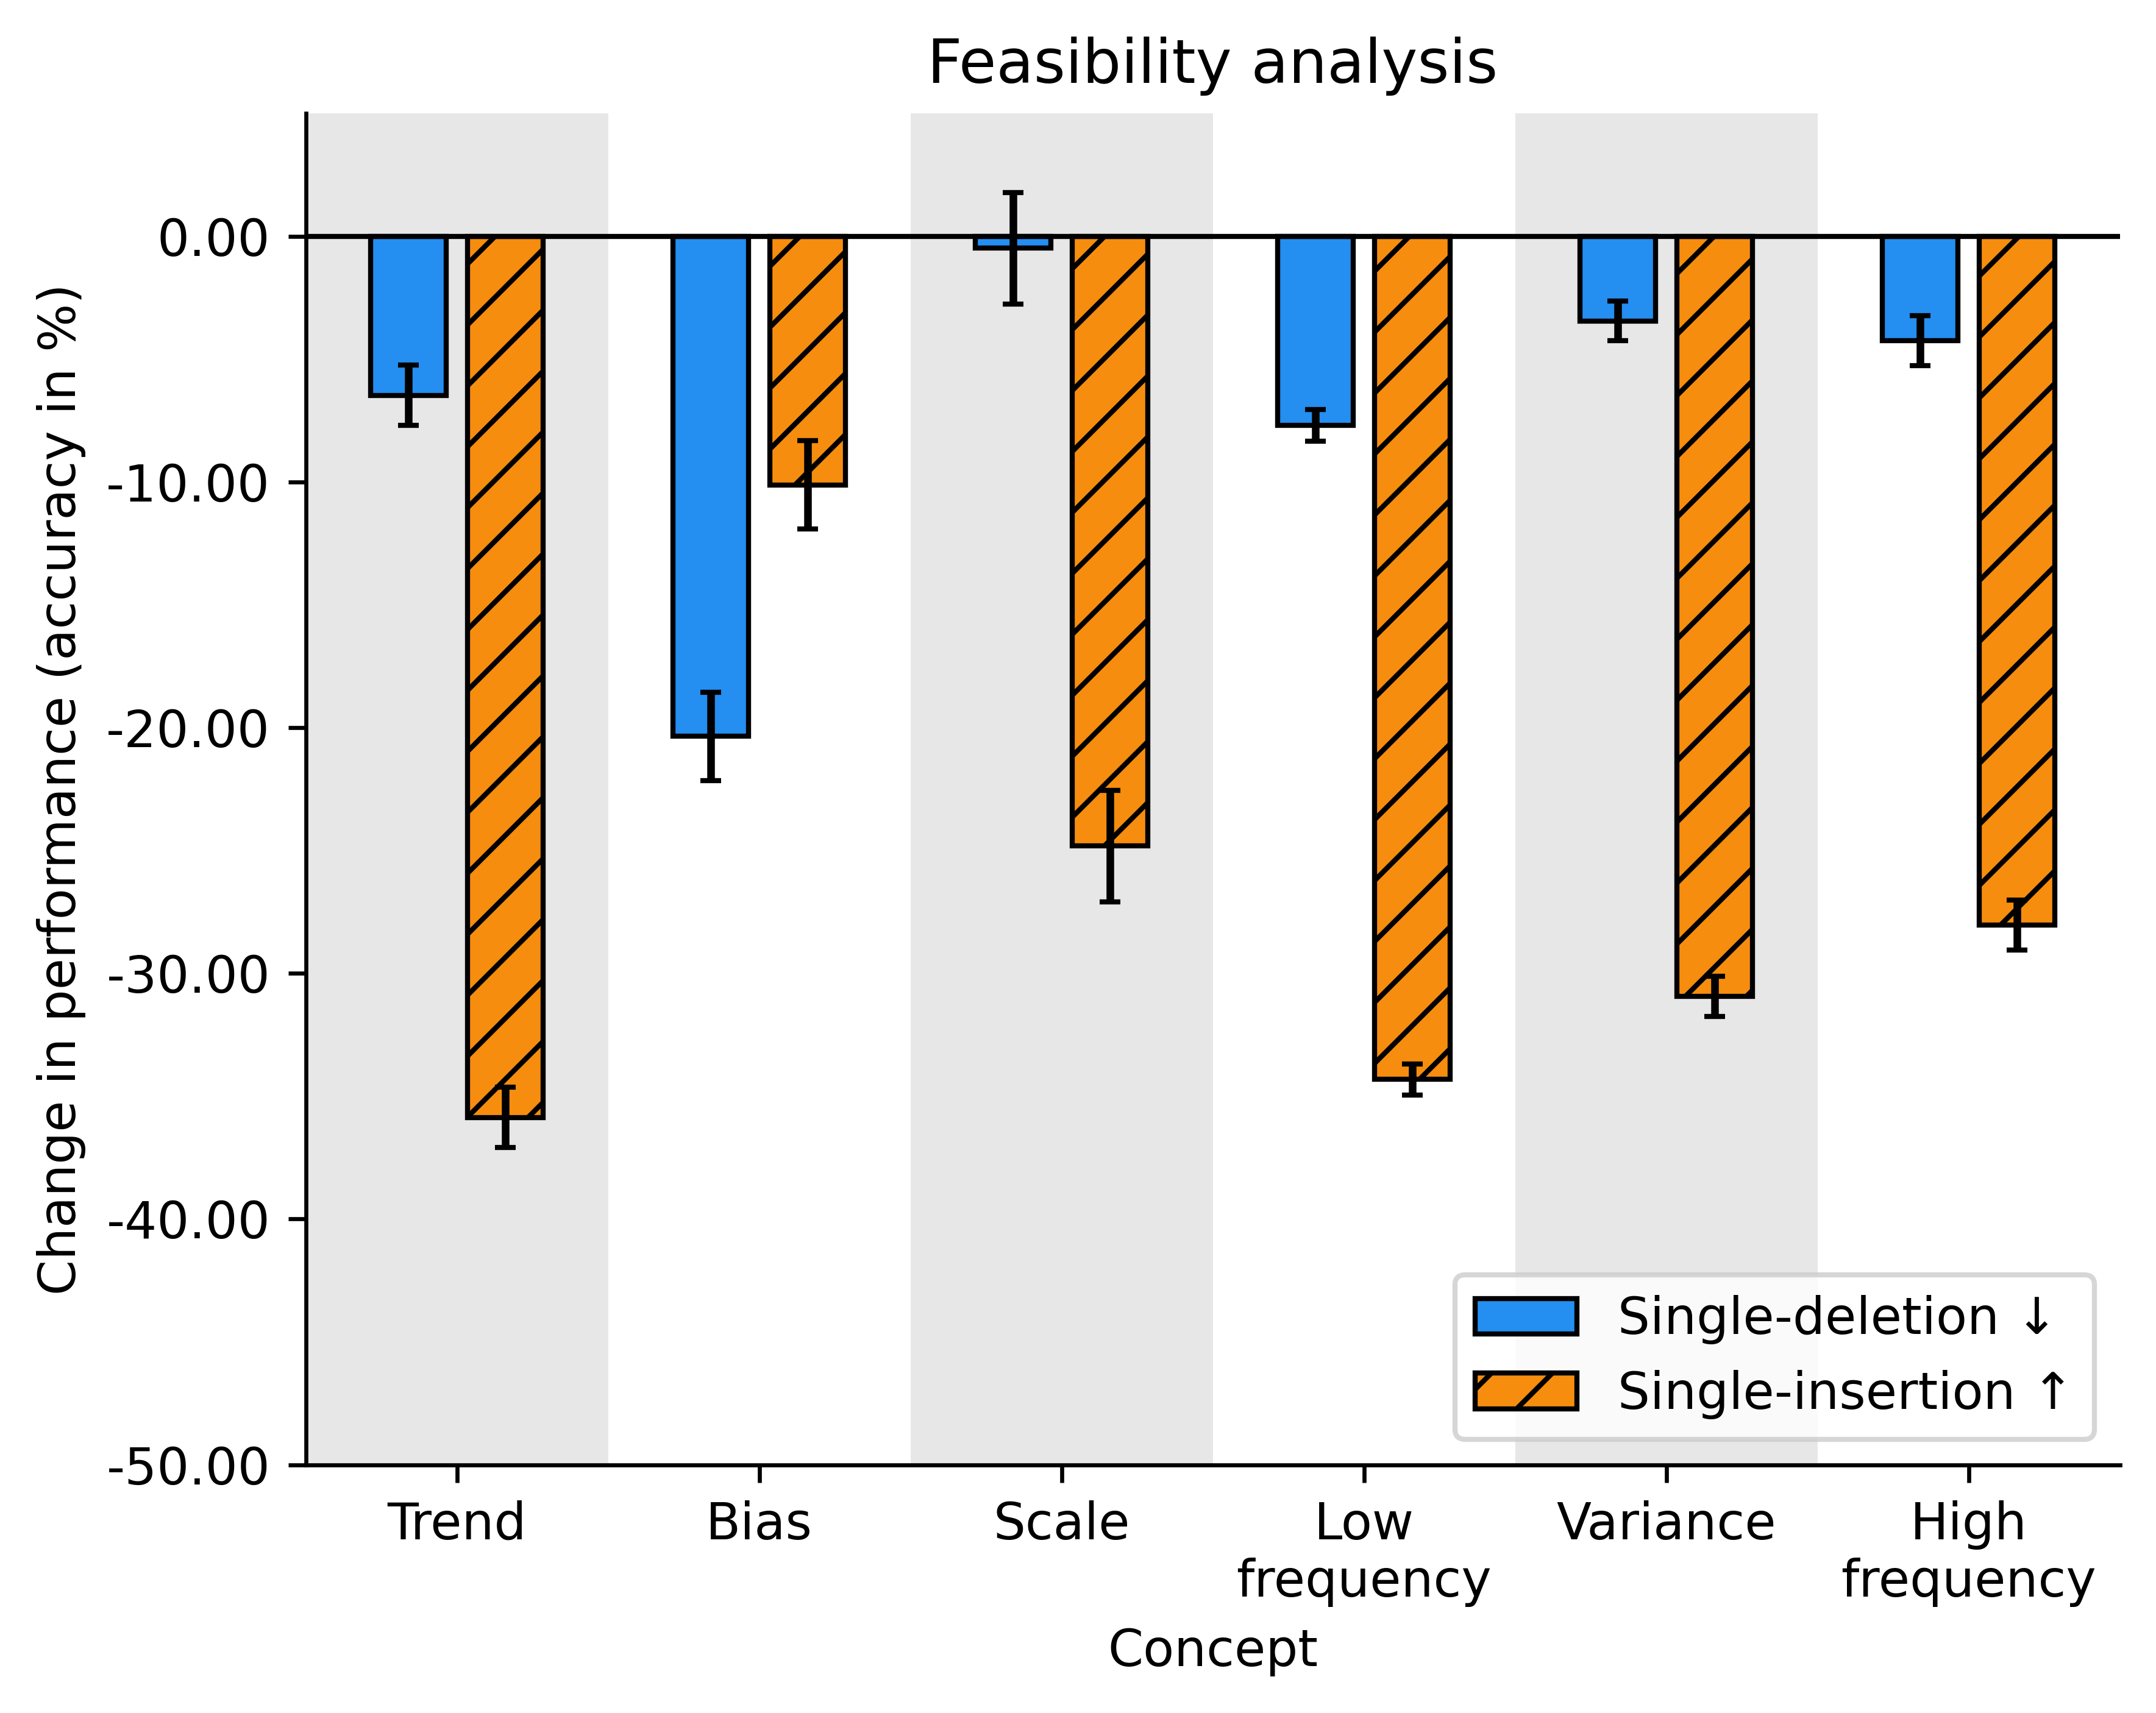

In [10]:
from matplotlib.ticker import FormatStrFormatter

fig, ax = plt.subplots(dpi=600)

if decomposition_def == 'DWT' or decomposition_def == 'EMD':
    components = decomposition.component_names
elif dataset == 'fordA':
    components = ['Scale', 'Low\nfrequency', 'Variance', 'High\nfrequency']
else:
    components = ['Trend', 'Bias', 'Scale', 'Low\nfrequency', 'Variance', 'High\nfrequency']

plt.xlim(-0.5, len(components) - 0.5)
plt.hlines(0, -1, len(mean_res_delete_opp) - 0.5, color='#000000', linewidth=1)
for i in range(len(decomposition.component_names)):
    if i % 2 == 0:
        plt.axvspan(i - 0.5, i + .5, facecolor='#D0D0D0', alpha=0.5)

# components = decomposition.component_names
y_pos = np.arange(len(components))

plt.ylim(-50, 5)

ax.bar(y_pos - 0.16, mean_res_delete_opp, align='center', width=0.25,
        capsize=2, color=colors[1], yerr=std_res_insert_opp, label='Single-deletion ↓', 
        edgecolor='k')
ax.bar(y_pos + 0.16, mean_res_insert_opp, align='center', width=0.25,
        capsize=2, color=colors[3], yerr=std_res_insert_opp, label='Single-insertion ↑',
        hatch='//', edgecolor='k')
ax.set_xticks(y_pos, labels=components)

# ax.invert_yaxis()
ax.set_ylabel('Performance')

ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
plt.ylabel('Change in performance (accuracy in %)')
plt.xlabel('Concept')

plt.legend();
plt.title('Feasibility analysis')

FordA

In [11]:
dataset = 'fordA'
decomposition_def = 'scale*(low_freq+var*high_freq)'
var_window_size = 50
noise_sigma = 1

In [12]:
if decomposition_def == 'EMD':
    decomposition = EMDDecomposition(max_imfs=4)
elif decomposition_def == 'DWT':
    decomposition = DWTDecomposition(level=3)
else:
    decomposition = CustomDecomposition(decomposition_def, noise_sigma=noise_sigma, var_window_size=var_window_size)

In [13]:
result_path = './../data/results/' + dataset + '/'

In [14]:
performance = 93.31

In [15]:
single_insertion_path = result_path + 'single_insertion.pkl'
single_deletion_path = result_path + 'single_deletion.pkl'

In [16]:
insert_res_dict = load_array(single_insertion_path)
delete_res_dict = load_array(single_deletion_path)

In [17]:
mean_res_insert_fordA = [np.mean(np.array(v) - performance) for v in insert_res_dict.values()]
std_res_insert_fordA = [np.std(np.array(v) - performance) for v in insert_res_dict.values()]

mean_res_delete_fordA = [np.mean(np.array(v) - performance) for v in list(delete_res_dict.values())[:-1]]
std_res_delete_fordA = [np.std(np.array(v) - performance) for v in list(delete_res_dict.values())[:-1]]

Text(0.5, 1.0, 'Feasibility analysis')

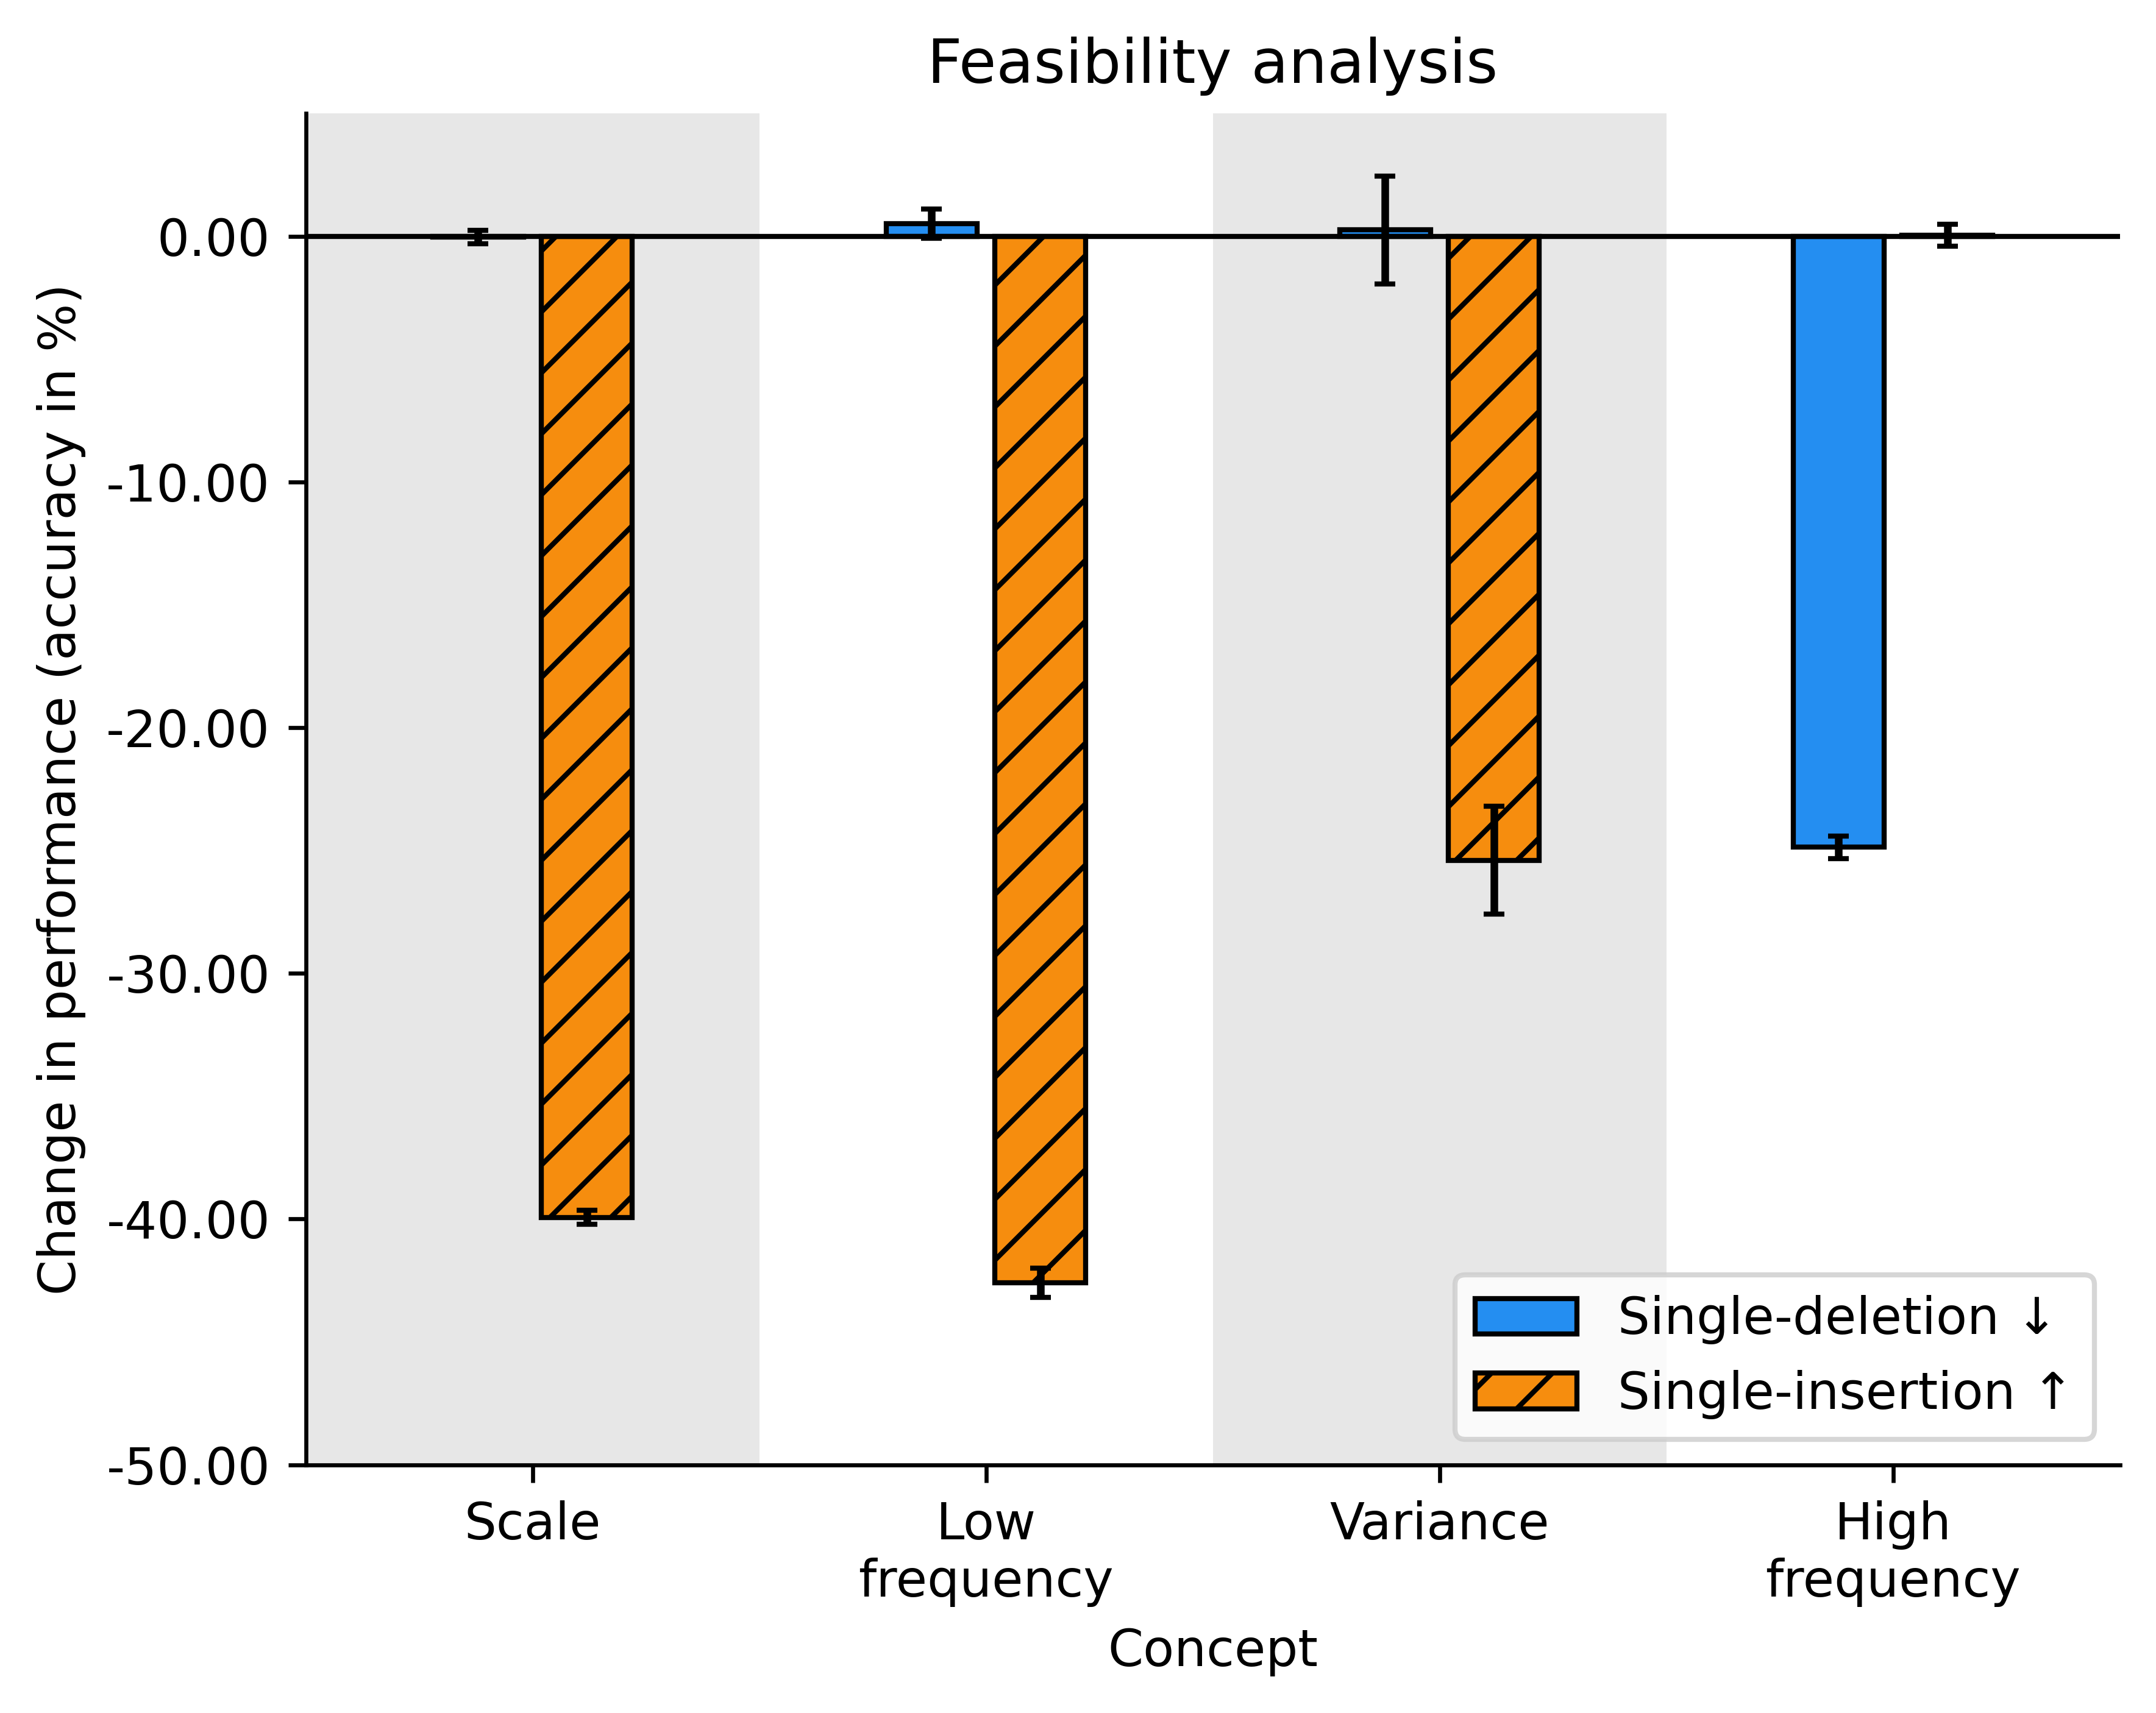

In [18]:
from matplotlib.ticker import FormatStrFormatter

fig, ax = plt.subplots(dpi=600)

if decomposition_def == 'DWT' or decomposition_def == 'EMD':
    components = decomposition.component_names
elif dataset == 'fordA':
    components = ['Scale', 'Low\nfrequency', 'Variance', 'High\nfrequency']
else:
    components = ['Trend', 'Bias', 'Scale', 'Low\nfrequency', 'Variance', 'High\nfrequency']

# components = decomposition.component_names
y_pos = np.arange(len(components))

plt.ylim(-50, 5)

plt.xlim(-0.5, len(components) - 0.5)
plt.hlines(0, -1, len(mean_res_delete_opp) - 0.5, color='#000000', linewidth=1)
for i in range(len(decomposition.component_names)):
    if i % 2 == 0:
        plt.axvspan(i - 0.5, i + .5, facecolor='#D0D0D0', alpha=0.5)

ax.bar(y_pos - 0.12, mean_res_delete_fordA, align='center', width=0.2,
        capsize=2, color=colors[1], yerr=std_res_insert_fordA, label='Single-deletion ↓',
        edgecolor='k')
ax.bar(y_pos + 0.12, mean_res_insert_fordA, align='center', width=0.2,
        capsize=2, color=colors[3], yerr=std_res_insert_fordA, label='Single-insertion ↑',
        hatch='//', edgecolor='k')
ax.set_xticks(y_pos, labels=components)

# ax.invert_xaxis()
ax.set_ylabel('Performance')

ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
plt.ylabel('Change in performance (accuracy in %)')
plt.xlabel('Concept')

plt.legend();
plt.title('Feasibility analysis')

Turbofan

In [19]:
dataset = 'turbofan'
decomposition_def = 'trend+bias+scale*(low_freq+var*high_freq)'
var_window_size = 30
noise_sigma = 1

In [20]:
if decomposition_def == 'EMD':
    decomposition = EMDDecomposition(max_imfs=4)
elif decomposition_def == 'DWT':
    decomposition = DWTDecomposition(level=3)
else:
    decomposition = CustomDecomposition(decomposition_def, noise_sigma=noise_sigma, var_window_size=var_window_size)

In [21]:
result_path = './../data/results/' + dataset + '/'

In [22]:
performance = 20.87

In [23]:
single_insertion_path = result_path + 'single_insertion.pkl'
single_deletion_path = result_path + 'single_deletion.pkl'

In [24]:
insert_res_dict = load_array(single_insertion_path)
delete_res_dict = load_array(single_deletion_path)

In [25]:
mean_res_insert_turbo = [np.mean(np.array(v) - performance) for v in insert_res_dict.values()]
std_res_insert_turbo = [np.std(np.array(v) - performance) for v in insert_res_dict.values()]

mean_res_delete_turbo = [np.mean(np.array(v) - performance) for v in list(delete_res_dict.values())[:-1]]
std_res_delete_turbo = [np.std(np.array(v) - performance) for v in list(delete_res_dict.values())[:-1]]

Text(0.5, 1.0, 'Feasibility analysis')

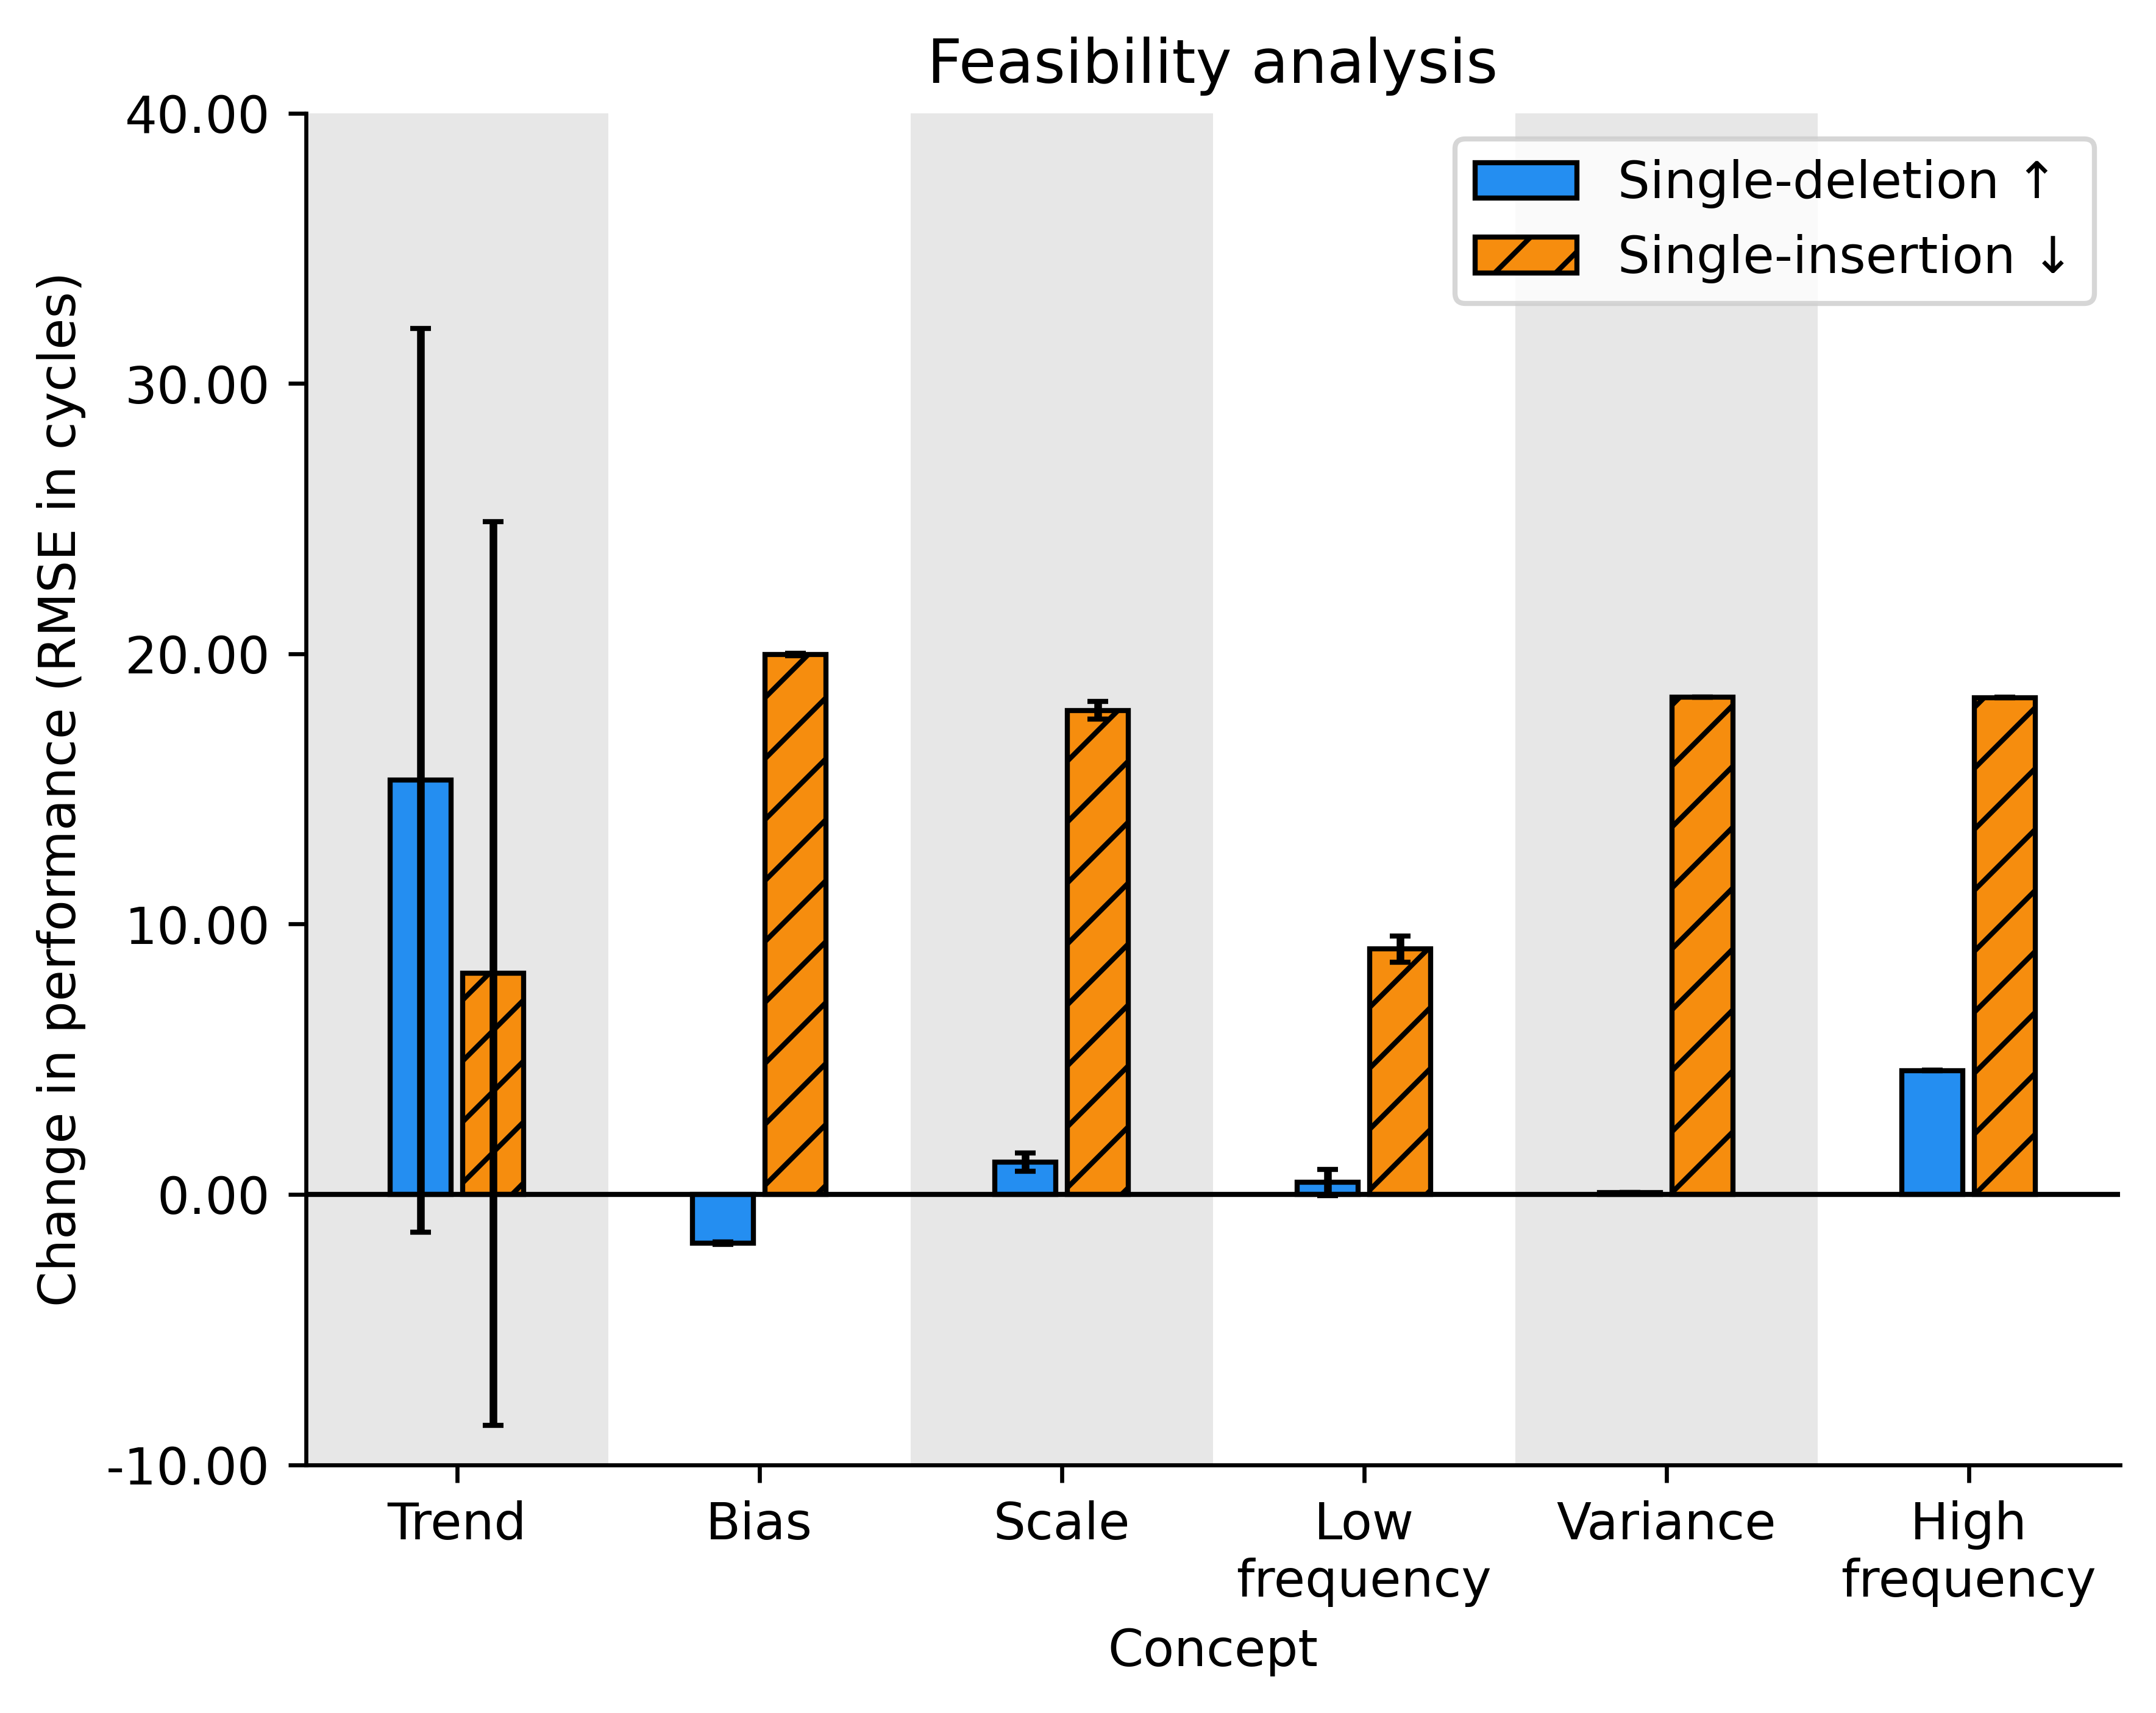

In [26]:
from matplotlib.ticker import FormatStrFormatter

fig, ax = plt.subplots(dpi=600)

if decomposition_def == 'DWT' or decomposition_def == 'EMD':
    components = decomposition.component_names
elif dataset == 'fordA':
    components = ['Scale', 'Low\nfrequency', 'Variance', 'High\nfrequency']
else:
    components = ['Trend', 'Bias', 'Scale', 'Low\nfrequency', 'Variance', 'High\nfrequency']

# components = decomposition.component_names
y_pos = np.arange(len(components))

plt.ylim(-10, 40)

plt.xlim(-0.5, len(components) - 0.5)
plt.hlines(0, -1, len(mean_res_delete_opp) - 0.5, color='#000000', linewidth=1)
for i in range(len(decomposition.component_names)):
    if i % 2 == 0:
        plt.axvspan(i - 0.5, i + .5, facecolor='#D0D0D0', alpha=0.5)

ax.bar(y_pos - 0.12, mean_res_delete_turbo, align='center', width=0.2,
        capsize=2, color=colors[1], yerr=std_res_insert_turbo, label='Single-deletion ↑',
        edgecolor='k')
ax.bar(y_pos + 0.12, mean_res_insert_turbo, align='center', width=0.2,
        capsize=2, color=colors[3], yerr=std_res_insert_turbo, hatch='//',
        edgecolor='k', label='Single-insertion ↓')
ax.set_xticks(y_pos, labels=components)

# ax.invert_xaxis()
ax.set_ylabel('Performance')

ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
plt.ylabel('Change in performance (RMSE in cycles)')
plt.xlabel('Concept')

plt.legend();
plt.title('Feasibility analysis')